# Perbandingan KNN — k=3, k=5, k=7 (BISINDO)
Membandingkan 3 varian KNN menggunakan semua metrik evaluasi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings,os,time,json
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
from sklearn.pipeline import Pipeline
warnings.filterwarnings('ignore');plt.rcParams['figure.dpi']=120
OUTPUT_DIR=r"E:\\Dokumen\\Kuliah\\Semester 5\\Pembelajaran Mesin\\Klasifikasi_Kelompok_1\\KNN\\outputKNNComparison";os.makedirs(OUTPUT_DIR,exist_ok=True)

In [2]:
data=np.load(r"E:\\Dokumen\\Kuliah\\Semester 5\\Pembelajaran Mesin\\Klasifikasi_Kelompok_1\\dataset_bisindo_landmarks.npz",allow_pickle=True)
X=np.nan_to_num(data['X'].astype(np.float32))
le=__import__('sklearn.preprocessing',fromlist=['LabelEncoder']).LabelEncoder()
y=le.fit_transform(data['labels'])
class_names=le.classes_
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
scaler=StandardScaler();X_tr=scaler.fit_transform(X_train);X_te=scaler.transform(X_test)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
print(f'Data siap: train={X_tr.shape[0]}, test={X_te.shape[0]}')

Data siap: train=6314, test=1579


In [3]:
results=[]
for k in [3,5,7]:
    knn=KNeighborsClassifier(n_neighbors=k,metric='euclidean',weights='distance',algorithm='ball_tree',n_jobs=-1)
    t0=time.time();knn.fit(X_tr,y_train);tt=time.time()-t0
    t0=time.time();yp=knn.predict(X_te);pt=time.time()-t0
    pipe=Pipeline([('sc',StandardScaler()),('knn',KNeighborsClassifier(n_neighbors=k,metric='euclidean',weights='distance',n_jobs=-1))])
    cvs=cross_val_score(pipe,X,y,cv=cv,scoring='f1_weighted',n_jobs=-1)
    results.append({'name':f'KNN (k={k})','k':k,'accuracy':accuracy_score(y_test,yp),
        'precision':precision_score(y_test,yp,average='weighted',zero_division=0),
        'recall':recall_score(y_test,yp,average='weighted',zero_division=0),
        'f1_score':f1_score(y_test,yp,average='weighted',zero_division=0),
        'cv_f1_mean':cvs.mean(),'cv_f1_std':cvs.std(),'train_time':tt,'pred_time':pt,'y_pred':yp})
    print(f'KNN k={k}: Acc={results[-1]["accuracy"]:.4f} F1={results[-1]["f1_score"]:.4f}')

KNN k=3: Acc=0.9614 F1=0.9612
KNN k=5: Acc=0.9550 F1=0.9547
KNN k=7: Acc=0.9506 F1=0.9503


In [4]:
df=pd.DataFrame([{k:v for k,v in r.items() if k!='y_pred'} for r in results])
display(df[['name','accuracy','precision','recall','f1_score','cv_f1_mean','cv_f1_std','train_time','pred_time']].style
    .format({'accuracy':'{:.4f}','precision':'{:.4f}','recall':'{:.4f}','f1_score':'{:.4f}',
             'cv_f1_mean':'{:.4f}','cv_f1_std':'{:.4f}','train_time':'{:.3f}','pred_time':'{:.3f}'})
    .highlight_max(subset=['accuracy','f1_score','cv_f1_mean'],color='#b8f0b8')
    .set_caption('Perbandingan KNN k=3,5,7'))

,name,accuracy,precision,recall,f1_score,cv_f1_mean,cv_f1_std,train_time,pred_time
0,KNN (k=3),0.9614,0.9619,0.9614,0.9612,0.9528,0.0017,0.074,0.242
1,KNN (k=5),0.9550,0.9558,0.9550,0.9547,0.9464,0.0030,0.070,0.298
2,KNN (k=7),0.9506,0.9513,0.9506,0.9503,0.9421,0.0027,0.067,0.265


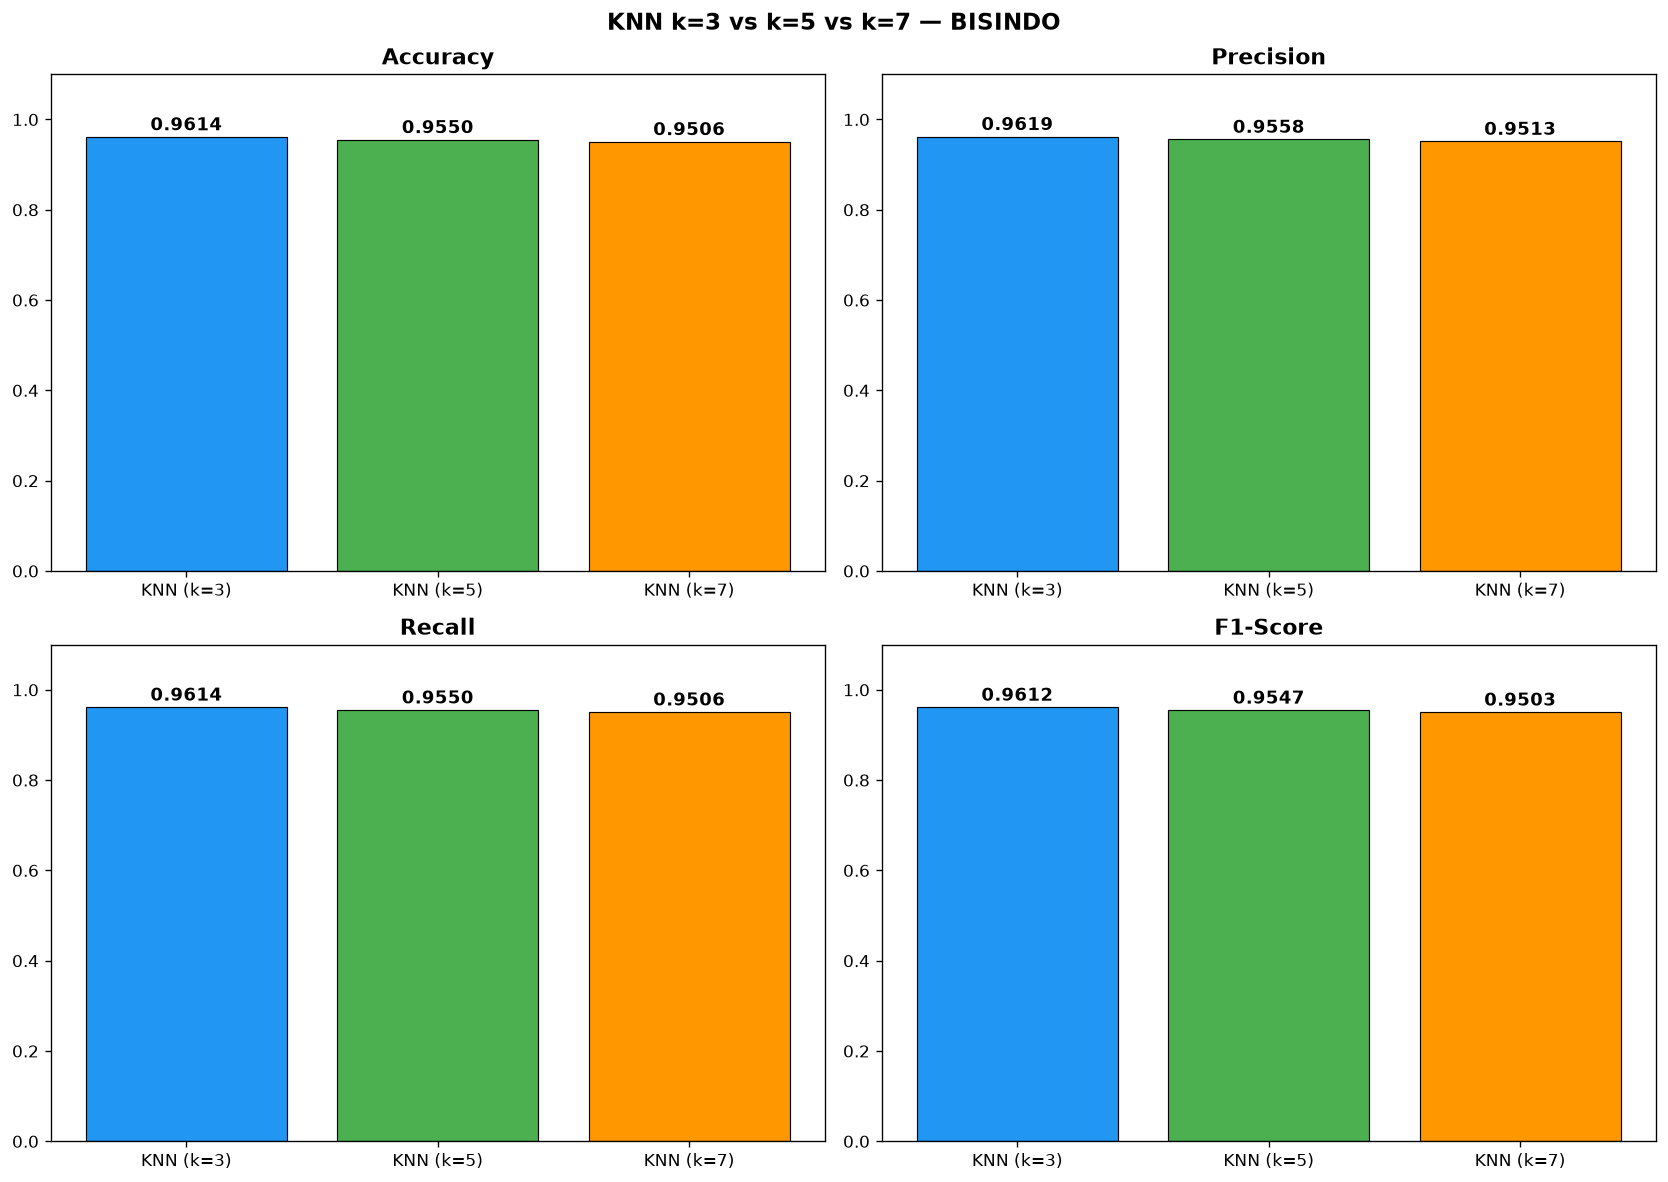

In [5]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
for ax,metric,label in zip(axes.flatten(),
    ['accuracy','precision','recall','f1_score'],['Accuracy','Precision','Recall','F1-Score']):
    vals=[r[metric] for r in results];names=[r['name'] for r in results]
    bars=ax.bar(names,vals,color=['#2196F3','#4CAF50','#FF9800'],edgecolor='black',lw=0.7)
    ax.set_ylim(0,1.1);ax.set_title(label,fontsize=13,fontweight='bold')
    for b,v in zip(bars,vals): ax.text(b.get_x()+b.get_width()/2,b.get_height()+0.005,f'{v:.4f}',ha='center',va='bottom',fontsize=11,fontweight='bold')
plt.suptitle('KNN k=3 vs k=5 vs k=7 — BISINDO',fontsize=14,fontweight='bold')
plt.tight_layout();plt.savefig(os.path.join(OUTPUT_DIR,'knn_comparison.png'),dpi=150,bbox_inches='tight');plt.show()

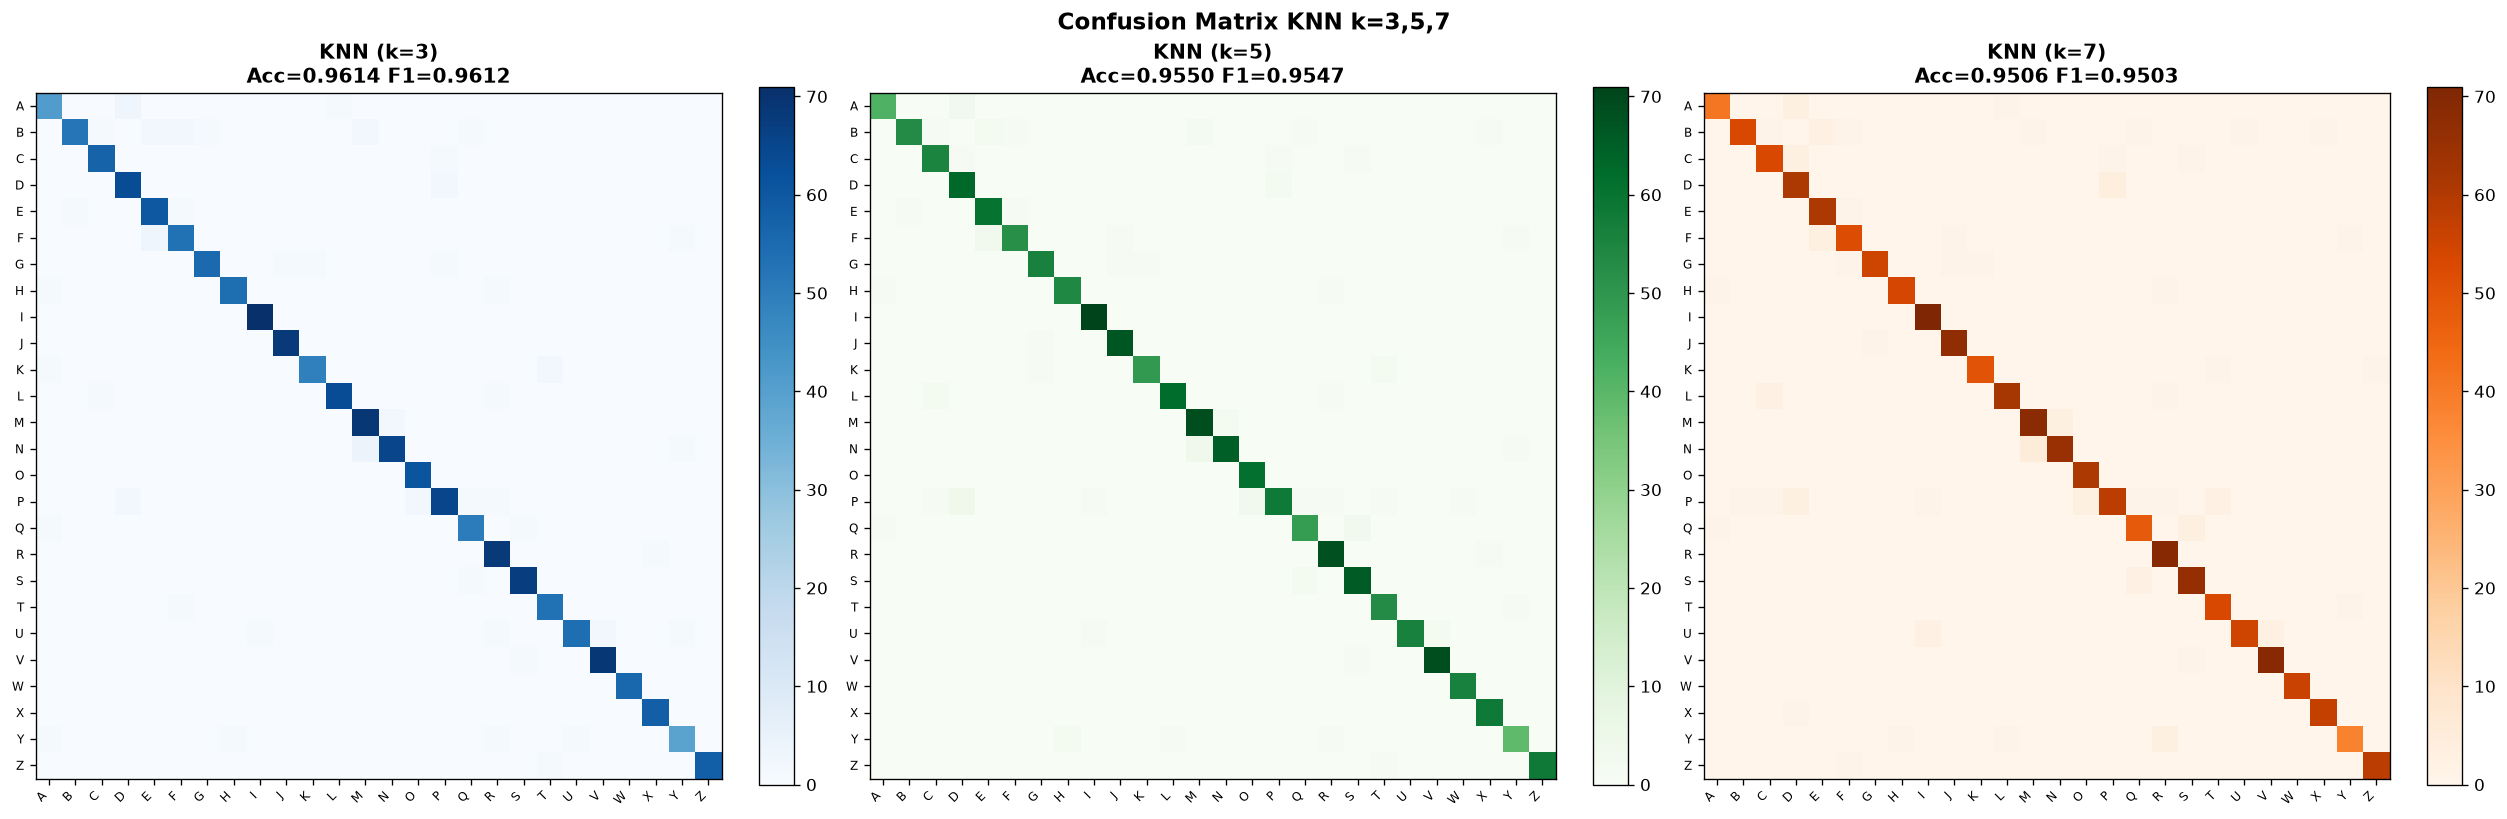

In [6]:
fig,axes=plt.subplots(1,3,figsize=(21,7))
cmaps=['Blues','Greens','Oranges']
for ax,r,cmap in zip(axes,results,cmaps):
    cm=confusion_matrix(y_test,r['y_pred'])
    im=ax.imshow(cm,cmap=cmap,interpolation='nearest')
    plt.colorbar(im,ax=ax,fraction=0.046)
    ax.set_xticks(range(len(class_names)));ax.set_xticklabels(class_names,rotation=45,ha='right',fontsize=7)
    ax.set_yticks(range(len(class_names)));ax.set_yticklabels(class_names,fontsize=7)
    ax.set_title(f"{r['name']}\nAcc={r['accuracy']:.4f} F1={r['f1_score']:.4f}",fontweight='bold')
plt.suptitle('Confusion Matrix KNN k=3,5,7',fontsize=14,fontweight='bold')
plt.tight_layout();plt.savefig(os.path.join(OUTPUT_DIR,'knn_cm_comparison.png'),dpi=150,bbox_inches='tight');plt.show()